In [ ]:
!pip install facenet-pytorch scikit-learn numpy pillow mtcnn matplotlib seaborn


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jessicali9530/lfw-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'lfw-dataset' dataset.
Path to dataset files: /kaggle/input/lfw-dataset


In [ ]:
import os
import numpy as np
import torch

from torchvision import transforms
from PIL import Image
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.Resize((160,160)),
    transforms.ToTensor()
])

lfw_dir = "/kaggle/input/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled"

from collections import Counter

# Count images in each identity folder
counts = Counter()
for person in os.listdir(lfw_dir):
    p_dir = os.path.join(lfw_dir, person)
    if os.path.isdir(p_dir):
        counts[person] = len(os.listdir(p_dir))

# Keep only people with at least 5 images
valid_ids = {p for p, c in counts.items() if c >= 5}
print("Valid identities with >=2 images:", len(valid_ids))


Valid identities with >=2 images: 423


In [ ]:
def build_dataset(root, valid_persons, transform):
    img_paths = []
    labels = []
    persons = sorted(list(valid_persons))
    person_to_idx = {p: i for i, p in enumerate(persons)}

    # Collect image paths and labels
    for p in persons:
        p_dir = os.path.join(root, p)
        for img in os.listdir(p_dir):
            img_path = os.path.join(p_dir, img)
            if os.path.isfile(img_path):  # Add this check to ensure it's a file
                img_paths.append(img_path)
                labels.append(person_to_idx[p])

    # PyTorch dataset
    class FilteredLFW(torch.utils.data.Dataset):
        def __init__(self, paths, labels, transform):
            self.paths = paths
            self.labels = labels
            self.transform = transform

        def __len__(self): return len(self.paths)

        def __getitem__(self, i):
            image = Image.open(self.paths[i]).convert("RGB")
            return self.transform(image), self.labels[i]

    return FilteredLFW(img_paths, labels, transform), len(persons)


transform = transforms.Compose([
    transforms.Resize((160,160)),
    transforms.ToTensor()
])

dataset, num_classes = build_dataset(lfw_dir, valid_ids, transform)
print("Dataset size:", len(dataset))
print("Number of classes (persons):", num_classes)


Dataset size: 5985
Number of classes (persons): 423


In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset, DataLoader

labels = np.array([lbl for _, lbl in dataset])
indices = np.arange(len(dataset))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    stratify=labels,
    random_state=42
)

train_ds = Subset(dataset, train_idx)
test_ds = Subset(dataset, test_idx)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

print("Train samples:", len(train_ds))
print("Test samples:", len(test_ds))


Train samples: 4788
Test samples: 1197


In [ ]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Running on device: {}'.format(device))

Running on device: cuda:0


In [ ]:
from facenet_pytorch import InceptionResnetV1

facenet = InceptionResnetV1(pretrained='vggface2').eval().to(device)
print("FaceNet loaded.")

  0%|          | 0.00/107M [00:00<?, ?B/s]

FaceNet loaded.


In [ ]:
def extract_embeddings(loader):
    embeddings, labels = [], []
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs = imgs.to(device)
            emb = facenet(imgs)
            embeddings.append(emb.cpu())
            labels.append(lbls)
    return torch.cat(embeddings).numpy(), torch.cat(labels).numpy()

X_train, y_train = extract_embeddings(train_loader)
X_test, y_test = extract_embeddings(test_loader)

print("Train embedding shape:", X_train.shape)
print("Test embedding shape:", X_test.shape)


Train embedding shape: (4788, 512)
Test embedding shape: (1197, 512)


In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

clf = make_pipeline(StandardScaler(), SVC(kernel="linear"))
clf.fit(X_train, y_train)

print("Training complete.")


Training complete.


Accuracy: 0.948203842940685

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       0.75      1.00      0.86         3
           2       1.00      1.00      1.00         1
           3       1.00      1.00      1.00         1
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         1
           6       1.00      1.00      1.00         1
           7       1.00      1.00      1.00         1
           8       1.00      1.00      1.00         1
           9       0.88      0.88      0.88         8
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         1
          12       1.00      1.00      1.00         7
          13       1.00      1.00      1.00         1
          14       0.80      1.00      0.89         4
          15       1.00      1.00      1.00         1
          16       1.00     

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


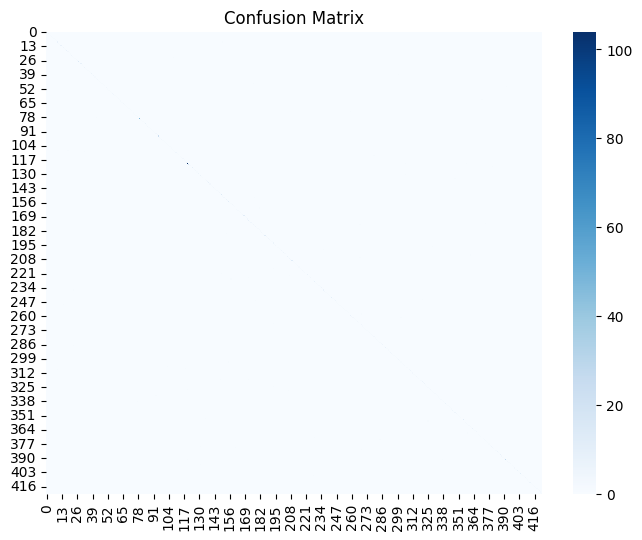

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
import joblib

joblib.dump(clf, "face_recognition_svm.pkl")
print("Model saved as face_recognition_svm.pkl")


Model saved as face_recognition_svm.pkl


In [ ]:
import json
from google.colab import files

# Reconstruct the person_to_idx mapping
persons = sorted(list(valid_ids))
person_to_idx = {p: i for i, p in enumerate(persons)}

# Save the label mapping to a JSON file
with open("label_mapping.json", "w") as f:
    json.dump(person_to_idx, f)

files.download("face_recognition_svm.pkl")
files.download("label_mapping.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
np.save("X_train.npy", X_train)
np.save("y_train.npy", y_train)
np.save("X_test.npy", X_test)
np.save("y_test.npy", y_test)

files.download("X_train.npy")
files.download("y_train.npy")
files.download("X_test.npy")
files.download("y_test.npy")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import joblib
joblib.dump(clf, "/content/drive/MyDrive/face_svm.pkl")


['/content/drive/MyDrive/face_svm.pkl']

In [ ]:
import joblib
import numpy as np
import torch # Import torch for saving PyTorch models

# 1. Save Facenet model (if needed)
torch.save(facenet.state_dict(), "facenet_embedder.pth") # Correct way to save a PyTorch model's state dictionary

# 2. Save embeddings
np.save("X_train_embeddings.npy", X_train)
np.save("X_test_embeddings.npy", X_test)
np.save("y_train.npy", y_train)
np.save("y_test.npy", y_test)

# 3. Save the trained SVM model
joblib.dump(clf, "svm_face_recognizer.pkl")

print("All checkpoints saved!")

All checkpoints saved!


In [ ]:
import joblib
import numpy as np
import torch
from facenet_pytorch import InceptionResnetV1

# Define device as it was defined before
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# 1. Load facenet model
# Re-initialize the model architecture first
facenet = InceptionResnetV1(pretrained='vggface2').eval().to(device)
facenet.load_state_dict(torch.load("facenet_embedder.pth")) # Load the state dictionary
facenet.eval() # Set to evaluation mode

# 2. Load embeddings
X_train = np.load("X_train_embeddings.npy") # Corrected filename
X_test = np.load("X_test_embeddings.npy")
y_train = np.load("y_train.npy")
y_test = np.load("y_test.npy")

# 3. Load SVM classifier
svm_clf = joblib.load("svm_face_recognizer.pkl") # Corrected filename

print("Checkpoint loaded successfully!")

Checkpoint loaded successfully!


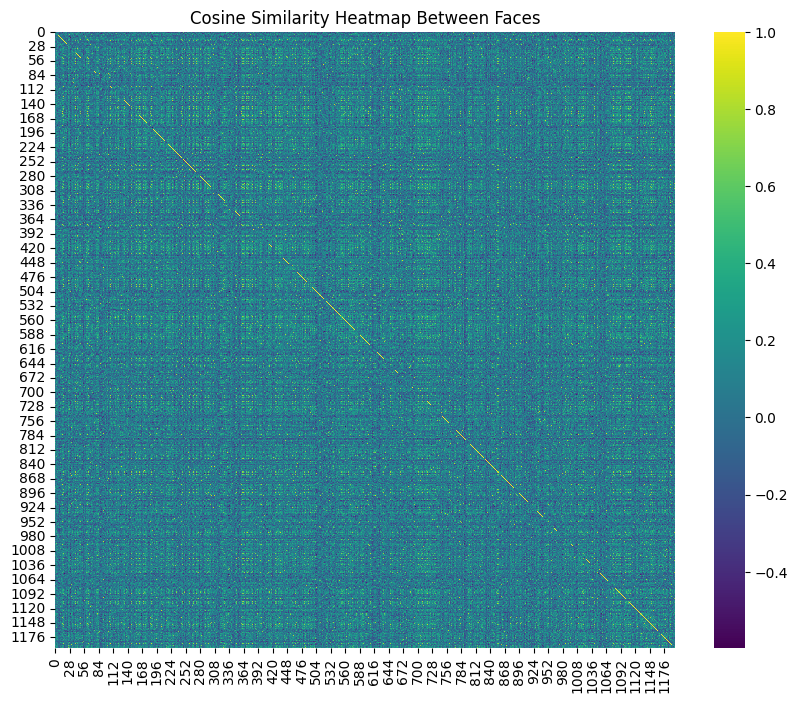

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(X_test)

plt.figure(figsize=(10, 8))
sns.heatmap(similarity_matrix, cmap='viridis')
plt.title("Cosine Similarity Heatmap Between Faces")
plt.show()


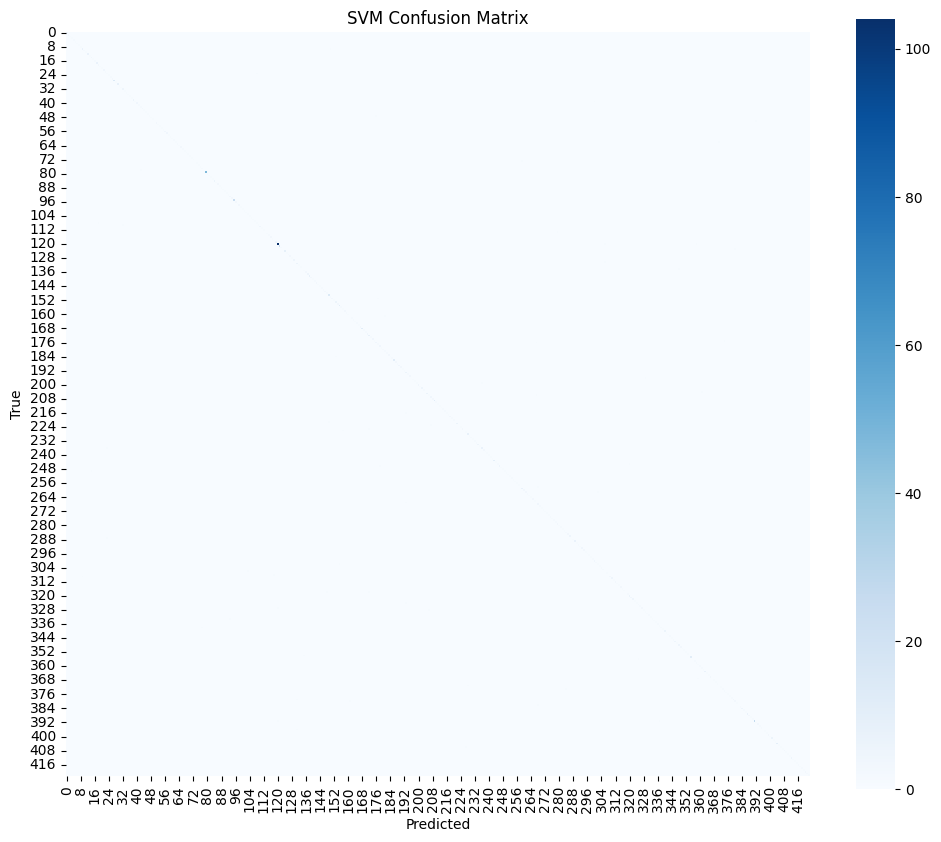

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = clf.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap='Blues', square=True)
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


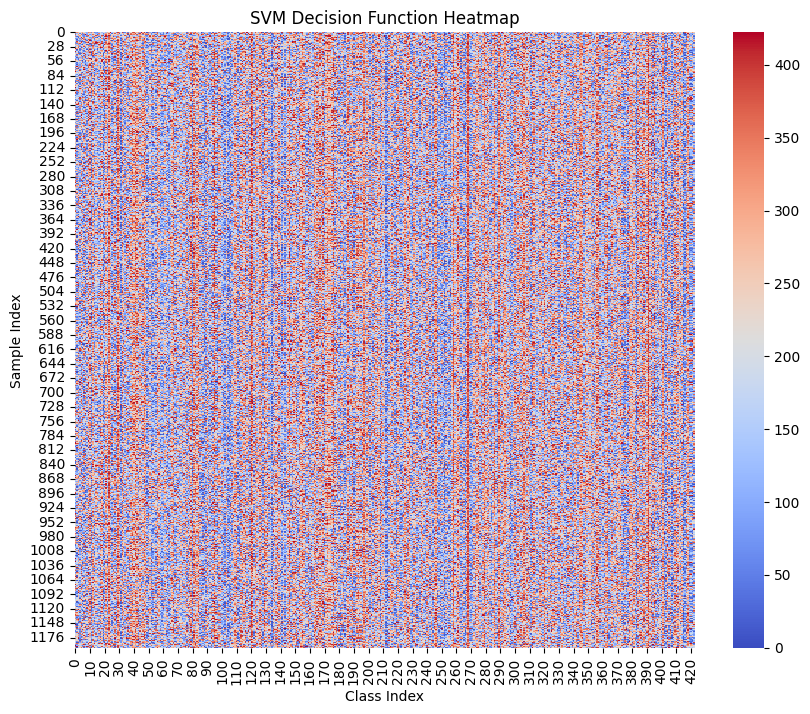

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# decision function values for each sample & class
decision_scores = svm_clf.decision_function(X_test)

plt.figure(figsize=(10, 8))
sns.heatmap(decision_scores, cmap='coolwarm')
plt.title("SVM Decision Function Heatmap")
plt.xlabel("Class Index")
plt.ylabel("Sample Index")
plt.show()


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_train_2D = pca.fit_transform(X_train)


In [ ]:
from sklearn.svm import SVC

svm_2D = SVC(kernel='linear')
svm_2D.fit(X_train_2D, y_train)
